# Diseño y Análisis de Experimentos
## Experimento $2^5$ no replicado: ejemplo integrador (Cap. 6)

**Contexto.** Planta de semiconductores: se quiere mejorar el rendimiento. Cinco factores a dos niveles, una sola corrida por tratamiento (32 corridas):

| Factor | Descripción | Niveles (−/+) |
|---|---|---|
| A | Abertura | pequeña / grande |
| B | Tiempo de exposición | 20% abajo / 20% arriba |
| C | Tiempo de revelado | 30 s / 45 s |
| D | Dimensión de la máscara | pequeña / grande |
| E | Tiempo de grabado | 14.5 min / 15.5 min |

El análisis se hizo en la calculadora del profesor (pestaña **Diseño Interactivo**, tipo *Screening (Factorial 2^k)*) y aquí se verifica con cálculo directo.

## 1. Datos (Tabla 6.14, orden estándar de Yates)

In [1]:
import itertools
import numpy as np
import pandas as pd
from scipy import stats

# Orden estándar: A cambia más rápido, E más lento
y = [7, 9, 34, 55, 16, 20, 40, 60,      # (1) a b ab c ac bc abc
     8, 10, 32, 50, 18, 21, 44, 61,     # d ad bd abd cd acd bcd abcd
     18, 12, 35, 52, 15, 22, 45, 65,    # e ae be abe ce ace bce abce
     6, 10, 30, 53, 15, 20, 41, 63]     # de ade bde abde cde acde bcde abcde

L = "ABCDE"
X = np.array([[1 if i >> b & 1 else -1 for b in range(5)] for i in range(32)])
df = pd.DataFrame(X, columns=list(L)); df["Y"] = y
df.head(8)

,A,B,C,D,E,Y
0,-1,-1,-1,-1,-1,7
1,1,-1,-1,-1,-1,9
2,-1,1,-1,-1,-1,34
3,1,1,-1,-1,-1,55
4,-1,-1,1,-1,-1,16
5,1,-1,1,-1,-1,20
6,-1,1,1,-1,-1,40
7,1,1,1,-1,-1,60


## 2. Efectos y sumas de cuadrados

Para un $2^k$ con una réplica: $\text{Efecto}=\dfrac{\text{Contraste}}{2^{k-1}}$ y $SC=\dfrac{\text{Contraste}^2}{2^k}$, con 1 grado de libertad por efecto.

In [2]:
filas = []
for r in range(1, 6):
    for c in itertools.combinations(range(5), r):
        signo = np.prod(X[:, c], axis=1)
        contraste = signo @ np.array(y)
        filas.append(("".join(L[i] for i in c), r, contraste / 16, contraste**2 / 32))
efectos = pd.DataFrame(filas, columns=["Efecto", "Orden", "Estimación", "SC"]).set_index("Efecto")
efectos.sort_values("SC", ascending=False).head(10).round(3)

,Orden,Estimación,SC
Efecto,,,
B,1,33.312,8877.781
A,1,11.188,1001.281
C,1,9.062,657.031
AB,2,8.562,586.531
DE,2,-1.812,26.281
BCDE,4,-1.562,19.531
BCE,3,1.562,19.531
CD,2,1.438,16.531
D,1,-1.438,16.531


Cuatro efectos dominan: **B, A, C y AB**. Las interacciones de tres factores o más son pequeñas.

## 3. ANOVA preliminar

Se agrupan las interacciones de **3 o más factores** como error (16 grados de libertad, el doble del mínimo recomendado). Si se incluyeran los 31 efectos no quedarían grados de libertad para el error.

In [3]:
sse = efectos.loc[efectos.Orden >= 3, "SC"].sum()
gle = int((efectos.Orden >= 3).sum())
mse = sse / gle
print(f"SCE = {sse:.2f} | gl error = {gle} | CME = {mse:.3f} | error estándar del efecto = {np.sqrt(mse/8):.3f}")

pre = efectos.loc[efectos.Orden <= 2, ["SC"]].copy()
pre["gl"] = 1
pre["CM"] = pre.SC
pre["F"] = pre.CM / mse
pre["p-valor"] = stats.f.sf(pre.F, 1, gle)
pre.loc["Error (3+ factores)"] = [sse, gle, mse, np.nan, np.nan]
pre.round(4)

SCE = 102.25 | gl error = 16 | CME = 6.391 | error estándar del efecto = 0.894


,SC,gl,CM,F,p-valor
Efecto,,,,,
A,1001.2812,1.0,1001.2812,156.6797,0.0000
B,8877.7812,1.0,8877.7812,1389.1883,0.0000
C,657.0312,1.0,657.0312,102.8117,0.0000
D,16.5312,1.0,16.5312,2.5868,0.1273
E,9.0312,1.0,9.0312,1.4132,0.2519
AB,586.5312,1.0,586.5312,91.7800,0.0000
AC,9.0312,1.0,9.0312,1.4132,0.2519
AD,2.5312,1.0,2.5312,0.3961,0.5380
AE,0.7812,1.0,0.7812,0.1222,0.7312


**Lectura.** Significativos con $\alpha=0.05$: **A, B, C y AB** (p ≈ 0). D, E, DE y el resto no lo son. La interacción **DE** queda como la duda del análisis (F ≈ 4.1, p ≈ 0.06 con estos datos).

## 4. Mejor ANOVA (modelo reducido)

Se eliminan los términos que no contribuyen y se conservan solo A, B, C y AB. Los efectos eliminados pasan al error (27 g.l.).

In [4]:
mejor = ["A", "B", "C", "AB"]
sc_mod = efectos.loc[mejor, "SC"]
sct = efectos["SC"].sum()
sce2 = sct - sc_mod.sum()
gle2 = 31 - len(mejor)
cme2 = sce2 / gle2

tabla = pd.DataFrame({"SC": sc_mod, "gl": 1, "CM": sc_mod})
tabla["F"] = tabla.CM / cme2
tabla["p-valor"] = stats.f.sf(tabla.F, 1, gle2)
tabla.loc["Residual"] = [sce2, gle2, cme2, np.nan, np.nan]
r2 = sc_mod.sum() / sct
r2aj = 1 - (sce2 / gle2) / (sct / 31)
display(tabla.round(4))
print(f"R² = {r2:.6f} | R² ajustado = {r2aj:.6f}")

,SC,gl,CM,F,p-valor
Efecto,,,,,
A,1001.2812,1.0,1001.2812,144.1124,0.0
B,8877.7812,1.0,8877.7812,1277.7616,0.0
C,657.0312,1.0,657.0312,94.5652,0.0
AB,586.5312,1.0,586.5312,84.4183,0.0
Residual,187.5938,27.0,6.9479,NaN,NaN


R² = 0.983414 | R² ajustado = 0.980957


## 5. Resultados de la calculadora del profesor

Pasos en la app (pestaña **Diseño Interactivo**):

1. Paso 1: *Screening (Factorial 2^k)*.
2. Paso 2: 5 factores, niveles −1 / +1.
3. Paso 3: respuesta = Rendimiento.
4. Paso 4: 1 réplica, 0 puntos centrales, sin randomizar (orden estándar).
5. Paso 5: carga de los 32 datos por CSV. El wizard usa A como columna más lenta, así que hubo que reordenar la Tabla 6.14.
6. Paso 6: ANOVA Tipo I → *Ejecutar Análisis*.
7. Paso 7: en *Refinamiento de efectos* se quitan las interacciones de 3+ factores → *Recalcular Modelo Reducido* (ANOVA preliminar), y luego se deja solo A, B, C, AB (mejor ANOVA).

**Observaciones:**

- Con los 31 efectos la app calcula el modelo saturado: sin g.l. de error no hay F ni p-valor (`MSE = nan`).
- Las SC, F y p-valores del ANOVA preliminar y del mejor ANOVA coinciden con el cálculo directo de arriba.
- Los gráficos de Pareto y Daniel de la app salen con etiquetas poco legibles (`B[T.1.0]C[T.1.0]…`).
- En la pestaña *Diseño 2^k* el refinamiento reinicia la página al cambiar la selección. En *Diseño Interactivo* funciona bien.

## 6. Gráficos de apoyo: Pareto y probabilidad normal de efectos

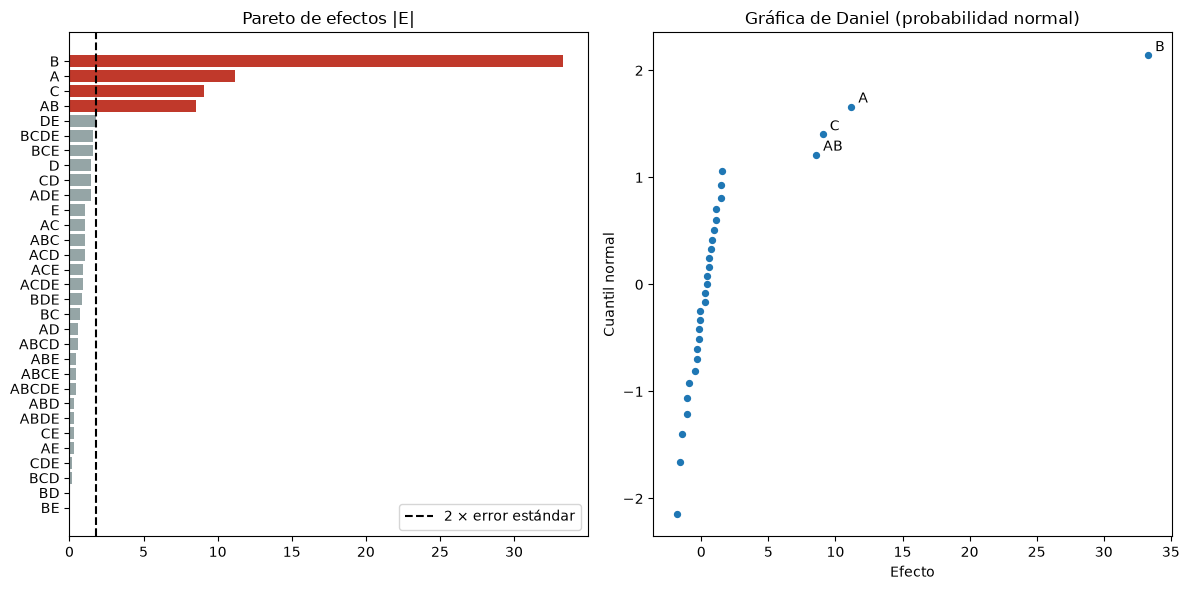

In [5]:
import matplotlib.pyplot as plt

ef = efectos["Estimación"]
orden = ef.abs().sort_values()
fig, ax = plt.subplots(1, 2, figsize=(12, 6))

ax[0].barh(orden.index, orden.values, color=["#c0392b" if k in mejor else "#95a5a6" for k in orden.index])
ax[0].axvline(2 * np.sqrt(mse / 8), ls="--", c="k", label="2 × error estándar")
ax[0].set_title("Pareto de efectos |E|"); ax[0].legend()

e = np.sort(ef.values); n = len(e)
q = stats.norm.ppf((np.arange(1, n + 1) - 0.5) / n)
ax[1].scatter(e, q, s=18)
for xi, qi, nombre in zip(e, q, ef.sort_values().index):
    if nombre in mejor:
        ax[1].annotate(nombre, (xi, qi), textcoords="offset points", xytext=(5, 3))
ax[1].set_title("Gráfica de Daniel (probabilidad normal)")
ax[1].set_xlabel("Efecto"); ax[1].set_ylabel("Cuantil normal")
plt.tight_layout(); plt.show()

## 7. Nota sobre el error estándar

El libro reporta $\hat\sigma_{efecto}=\sqrt{2.48/(1\times2^{5-2})}=0.557$. Con los datos de la Tabla 6.14 tal como aparecen en la imagen, el cálculo da $CME=6.39$ y $\hat\sigma_{efecto}=0.894$. La discrepancia **no** viene de la calculadora (coincide con el cálculo directo). Conviene revisar contra el libro si los datos o el CME reportado difieren.

## 8. Conclusión

Solo **A (abertura), B (tiempo de exposición), C (tiempo de revelado) y la interacción AB** afectan significativamente el rendimiento. B es por mucho el más influyente. D, E y sus interacciones pueden fijarse por conveniencia, con la interacción DE como único punto a vigilar.